In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
num_arrays = 6

# Create an array of zeros
p_arrays_1 = np.zeros((num_arrays, 6))

# Fill each array with the desired values
for i in range(num_arrays):
    p_arrays_1[i, i] = 0.19
    p_arrays_1[i, (i + 1) % 6] = 0.19
    p_arrays_1[i, (i + 2) % 6] = 0.19
    p_arrays_1[i, (i + 3) % 6] = 0.19
    p_arrays_1[i, (i + 4) % 6] = 0.19
    p_arrays_1[i, (i + 5) % 6] = 0.05

In [3]:
# Number of p arrays you want to create
num_arrays = 6

# Create an array of zeros
p_arrays_2 = np.zeros((num_arrays, 6))

# Fill each array with the desired values
for i in range(num_arrays):
    p_arrays_2[i, i] = 0.28
    p_arrays_2[i, (i + 1) % 6] = 0.28
    p_arrays_2[i, (i + 2) % 6] = 0.28
    p_arrays_2[i, (i + 3) % 6] = 0.06
    p_arrays_2[i, (i + 4) % 6] = 0.04
    p_arrays_2[i, (i + 5) % 6] = 0.06

In [4]:
combined_p_arrays = np.vstack((p_arrays_1, p_arrays_2))
#num_arrays = combined_p_arrays.shape[0]

In [5]:
for i, p in enumerate(combined_p_arrays):
    print(f"p{i+1} =", p)

p1 = [0.19 0.19 0.19 0.19 0.19 0.05]
p2 = [0.05 0.19 0.19 0.19 0.19 0.19]
p3 = [0.19 0.05 0.19 0.19 0.19 0.19]
p4 = [0.19 0.19 0.05 0.19 0.19 0.19]
p5 = [0.19 0.19 0.19 0.05 0.19 0.19]
p6 = [0.19 0.19 0.19 0.19 0.05 0.19]
p7 = [0.28 0.28 0.28 0.06 0.04 0.06]
p8 = [0.06 0.28 0.28 0.28 0.06 0.04]
p9 = [0.04 0.06 0.28 0.28 0.28 0.06]
p10 = [0.06 0.04 0.06 0.28 0.28 0.28]
p11 = [0.28 0.06 0.04 0.06 0.28 0.28]
p12 = [0.28 0.28 0.06 0.04 0.06 0.28]


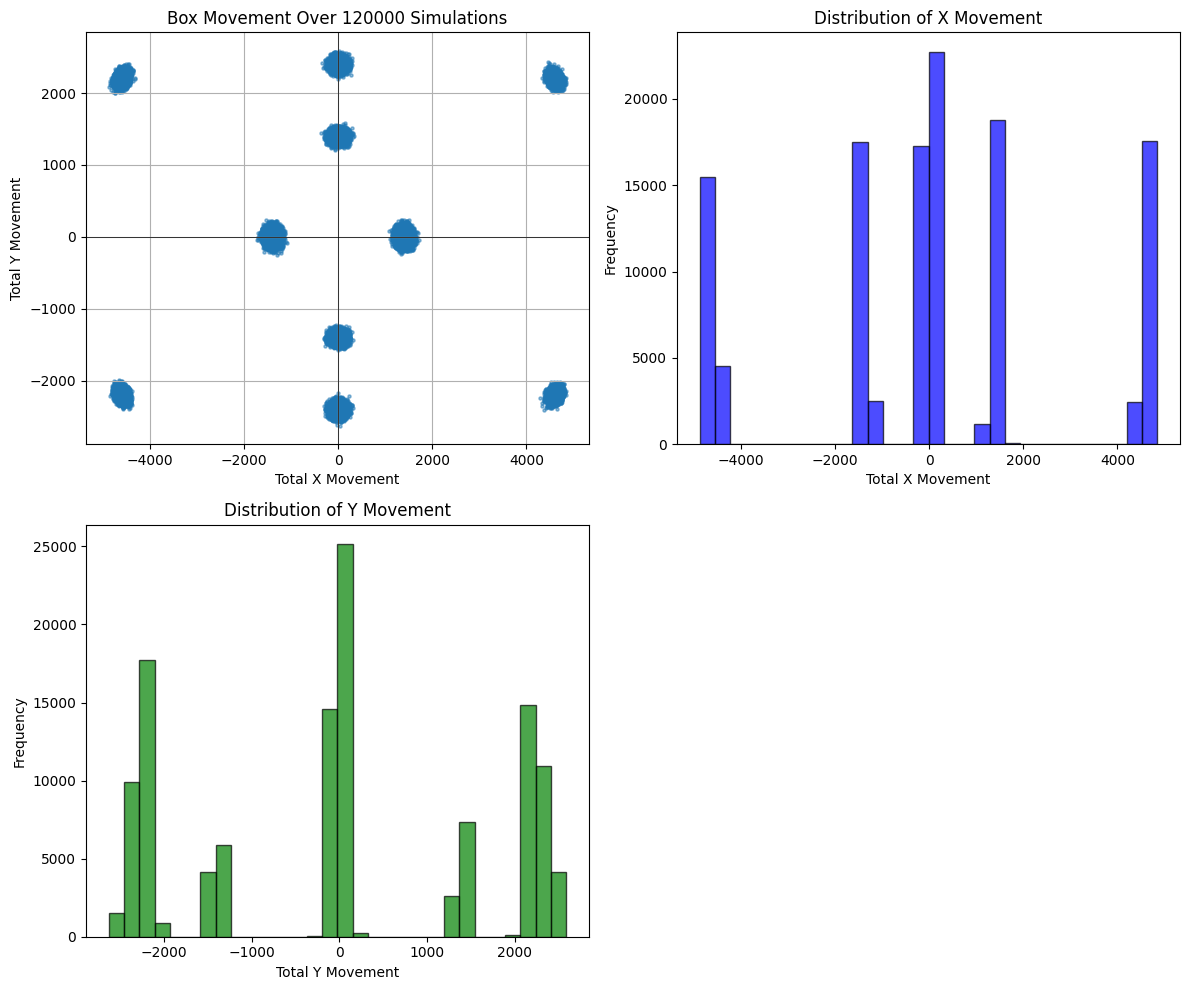

In [6]:
# Define the box dynamics
region_movements = {
    1: (0, -1),
    2: (-1, 0),
    3: (-1, 0),
    4: (0, 1),
    5: (1, 0),
    6: (1, 0)
}

# Number of simulations per distribution
num_simulations = 10000
num_distributions = combined_p_arrays.shape[0]
num_agents = 10000

# Arrays to store cumulative movements
cumulative_x_movement = np.zeros(num_simulations * num_distributions)
cumulative_y_movement = np.zeros(num_simulations * num_distributions)

# Perform simulations
for i in range(num_simulations * num_distributions):
    # Generate random region selections based on probabilities
    p = combined_p_arrays[i % num_distributions]
    agent_regions = np.random.choice(list(region_movements.keys()), size=num_agents, p=p) #100 s

    # Calculate net movements in x and y directions
    total_x_movement = sum(region_movements[region][0] for region in agent_regions)
    total_y_movement = sum(region_movements[region][1] for region in agent_regions)

    # Store cumulative movements
    cumulative_x_movement[i] = total_x_movement
    cumulative_y_movement[i] = total_y_movement

# Create figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot for scatter of x vs y movement
axs[0, 0].scatter(cumulative_x_movement, cumulative_y_movement, s=5, alpha=0.5)
axs[0, 0].set_title('Box Movement Over ' + str(num_simulations * num_distributions) + ' Simulations')
axs[0, 0].set_xlabel('Total X Movement')
axs[0, 0].set_ylabel('Total Y Movement')
axs[0, 0].grid(True)
axs[0, 0].axhline(0, color='black', linewidth=0.5)
axs[0, 0].axvline(0, color='black', linewidth=0.5)

# Plot for x movement histogram
axs[0, 1].hist(cumulative_x_movement, bins=30, color='blue', edgecolor='black', alpha=0.7)
axs[0, 1].set_title('Distribution of X Movement')
axs[0, 1].set_xlabel('Total X Movement')
axs[0, 1].set_ylabel('Frequency')

# Plot for y movement histogram
axs[1, 0].hist(cumulative_y_movement, bins=30, color='green', edgecolor='black', alpha=0.7)
axs[1, 0].set_title('Distribution of Y Movement')
axs[1, 0].set_xlabel('Total Y Movement')
axs[1, 0].set_ylabel('Frequency')

# Remove the empty subplot space
fig.delaxes(axs[1, 1])

plt.tight_layout()
plt.show()

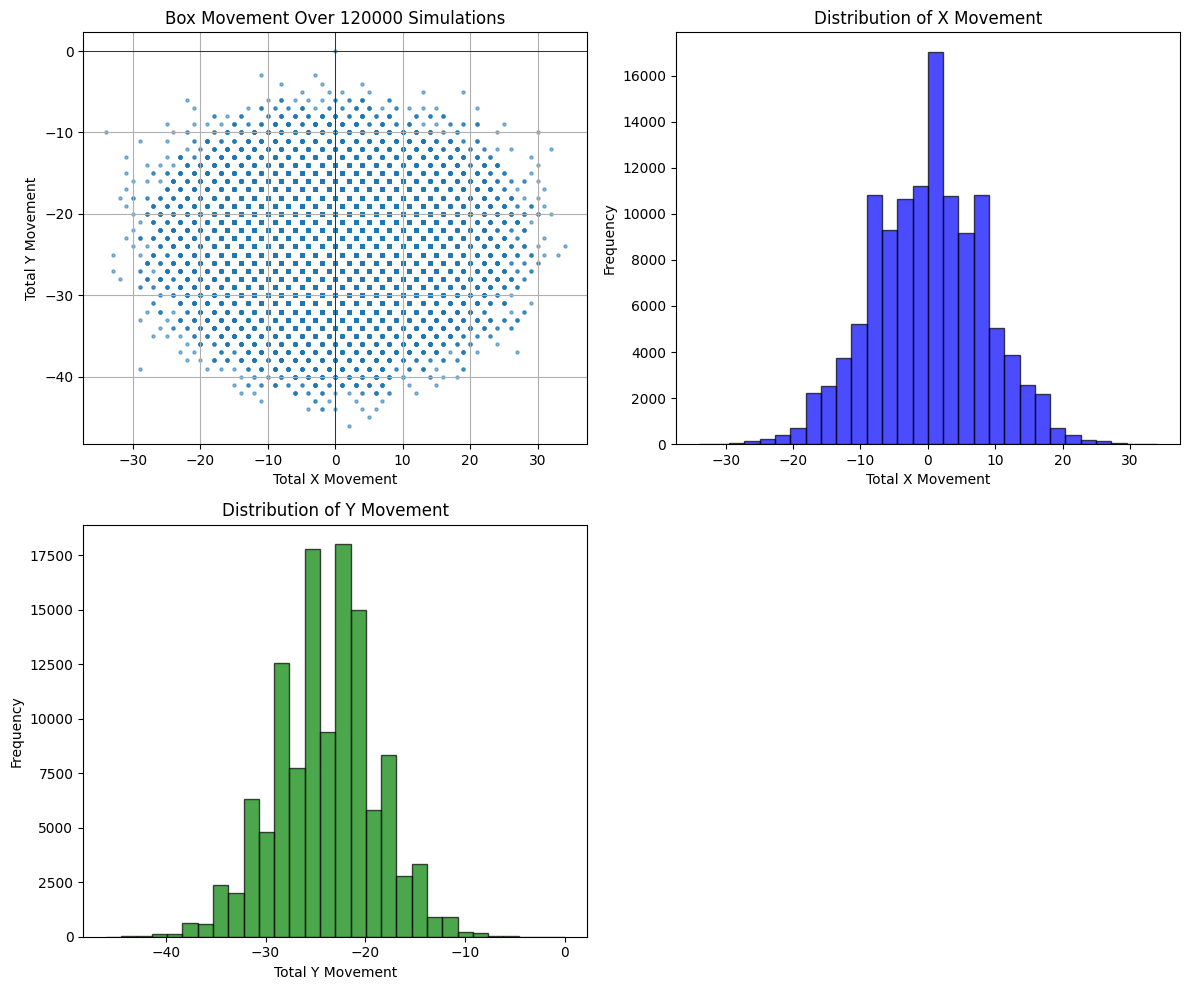

In [7]:
# Define the box dynamics
region_movements = {
    1: (0, -1),
    2: (-1, 0),
    3: (-1, 0),
    4: (0, 1),
    5: (1, 0),
    6: (1, 0)
}

# Number of simulations per distribution
num_simulations = 10000
num_distributions = 12
num_agents = 100

# Arrays to store cumulative movements
cumulative_x_movement = np.zeros(num_simulations * num_distributions)
cumulative_y_movement = np.zeros(num_simulations * num_distributions)

# Perform simulations
for i in range(num_simulations * num_distributions):
    # Generate random region selections based on probabilities
    #p = combined_p_arrays[i % num_distributions]
    agent_regions = np.random.choice(list(region_movements.keys()), size=num_agents, p=p) #100 s

    # Calculate net movements in x and y directions
    total_x_movement = sum(region_movements[region][0] for region in agent_regions)
    total_y_movement = sum(region_movements[region][1] for region in agent_regions)

    # Store cumulative movements
    cumulative_x_movement[i] = total_x_movement
    cumulative_y_movement[i] = total_y_movement

# Create figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot for scatter of x vs y movement
axs[0, 0].scatter(cumulative_x_movement, cumulative_y_movement, s=5, alpha=0.5)
axs[0, 0].set_title('Box Movement Over ' + str(num_simulations * num_distributions) + ' Simulations')
axs[0, 0].set_xlabel('Total X Movement')
axs[0, 0].set_ylabel('Total Y Movement')
axs[0, 0].grid(True)
axs[0, 0].axhline(0, color='black', linewidth=0.5)
axs[0, 0].axvline(0, color='black', linewidth=0.5)

# Plot for x movement histogram
axs[0, 1].hist(cumulative_x_movement, bins=30, color='blue', edgecolor='black', alpha=0.7)
axs[0, 1].set_title('Distribution of X Movement')
axs[0, 1].set_xlabel('Total X Movement')
axs[0, 1].set_ylabel('Frequency')

# Plot for y movement histogram
axs[1, 0].hist(cumulative_y_movement, bins=30, color='green', edgecolor='black', alpha=0.7)
axs[1, 0].set_title('Distribution of Y Movement')
axs[1, 0].set_xlabel('Total Y Movement')
axs[1, 0].set_ylabel('Frequency')

# Remove the empty subplot space
fig.delaxes(axs[1, 1])

plt.tight_layout()
plt.show()